# 04 K-Means clustering
New dataset: change `DATA` and `TARGET`. Labels are only used for ARI / NMI.

## 1. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

warnings.filterwarnings("ignore")

In [2]:
DATA = "data/breast_cancer.csv"
TARGET = "diagnosis"

In [3]:
df = pd.read_csv(DATA)
df.shape

(569, 31)

## 2. EDA

In [4]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [6]:
print(df.isnull().sum().sum())
print(df.duplicated().sum())

0
0


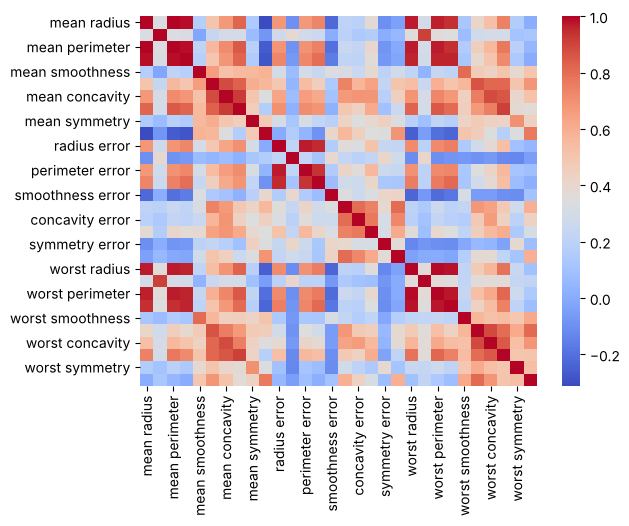

In [7]:
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.show()

## 3. Preprocessing

In [8]:
df = df.drop_duplicates()

In [9]:
y_true = LabelEncoder().fit_transform(df[TARGET])
X = pd.get_dummies(df.drop(columns=TARGET), drop_first=True)
X = X.fillna(X.median())

In [10]:
X_scaled = StandardScaler().fit_transform(X)

## 4. Choose k

In [11]:
ks = range(2, 11)
wcss = []
silhouette = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)
    silhouette.append(silhouette_score(X_scaled, model.labels_))

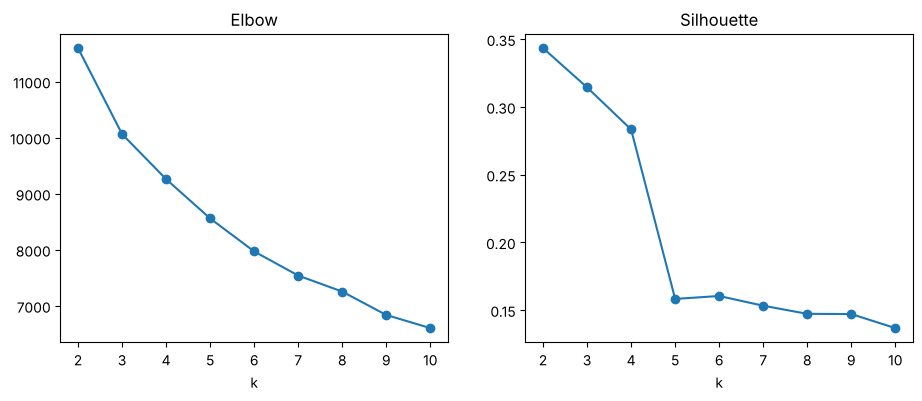

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, wcss, marker="o")
ax[0].set(title="Elbow", xlabel="k")
ax[1].plot(ks, silhouette, marker="o")
ax[1].set(title="Silhouette", xlabel="k")
plt.show()

In [13]:
best_k = ks[int(np.argmax(silhouette))]
print(best_k)

2


## 5. Final K-Means

In [14]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_scaled)

In [15]:
print("WCSS:", round(kmeans.inertia_, 1))
print("Silhouette:", round(silhouette_score(X_scaled, labels), 4))
print(
    "Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled, labels), 1)
)
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, labels), 4))

WCSS: 11595.5
Silhouette: 0.3434
Calinski-Harabasz: 267.7
Davies-Bouldin: 1.3205


In [16]:
print("ARI:", round(adjusted_rand_score(y_true, labels), 4))
print("NMI:", round(normalized_mutual_info_score(y_true, labels), 4))

ARI: 0.6536
NMI: 0.5324


In [17]:
pd.crosstab(labels, y_true)

col_0,0,1
row_0,,
0,339,36
1,18,176


## 6. Scaled vs Unscaled

In [18]:
unscaled = KMeans(n_clusters=best_k, n_init=10, random_state=42)
labels_unscaled = unscaled.fit_predict(X)
print("ARI unscaled:", round(adjusted_rand_score(y_true, labels_unscaled), 4))
print("ARI scaled:", round(adjusted_rand_score(y_true, labels), 4))

ARI unscaled: 0.4914
ARI scaled: 0.6536


## 7. PCA and K-Means

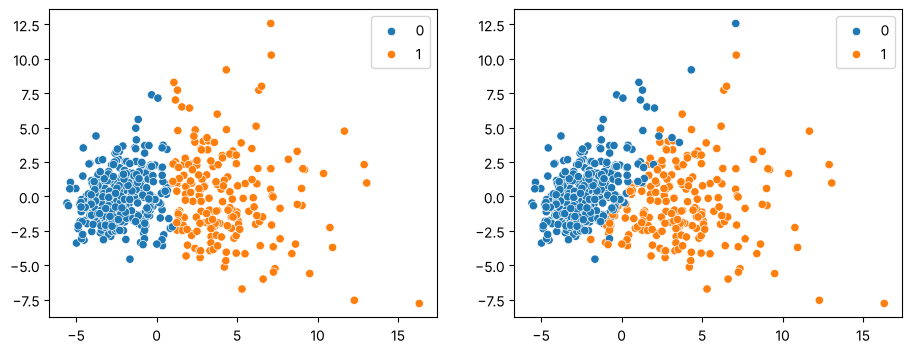

In [19]:
X_2d = PCA(n_components=2).fit_transform(X_scaled)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=labels, ax=ax[0])
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y_true, ax=ax[1])
plt.show()

In [20]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)
print(X_scaled.shape[1], "->", pca.n_components_)

30 -> 10


In [21]:
labels_pca = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(
    X_pca
)
print("Silhouette:", round(silhouette_score(X_pca, labels_pca), 4))
print("ARI:", round(adjusted_rand_score(y_true, labels_pca), 4))

Silhouette: 0.358
ARI: 0.6707
